In [1]:
%load_ext autoreload 
%autoreload 2

from galfits.gsutils import read_config_file
from pathlib import Path
import numpy as np
from astropy.io import ascii
from typing import Literal
from plot_utils import fig_grid, show_image,normimg,  set_plot_style, forward, inverse, B
from utils import Ll38_to_flam, fconts_to_SFH
from photutils.segmentation import detect_sources
from astropy.stats import sigma_clipped_stats
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib import colors as mcolors

set_plot_style()

import warnings
warnings.filterwarnings("ignore")

## 0. Loadiiing GalfitS Information container
- Take a image - SED fitting for `LRDs_CEERS_49140` for example

In [2]:
root_dir    = Path("./cutouts/")
lyric_path  = root_dir  / "obj49140_imagesed.lyric"
workplace   = root_dir  / "wp_imagesed"
prior       = root_dir  / "obj49140.prior"
gssum_path  = workplace / "obj49140_imagesed_NPagn.gssummary"

Myfitter, targname, functring   = read_config_file(config = lyric_path, workplace = workplace, priorpath = prior, silent=True)
gssm    = ascii.read(gssum_path) ## astropy.io.ascii. Import manually first. 

for loop_s in range(len(gssm)):
    try:
        Myfitter.lmParameters[gssm["pname"][loop_s]].value  = gssm["best_value"][loop_s] # update lmparameter.
    except KeyError:
        skip_key    = gssm["pname"][loop_s]
        print(f"skip {skip_key} !")
Myfitter.loose_fix_pars() # here update pardict.

for loop_m, model in enumerate(Myfitter.model_list):
    if Myfitter.mtype_list[loop_m] == "galaxy":
        for subC in model.subnames:
            model.update_subC_para(subC, Myfitter.pardict) # here update params in galaxy model. 


No additional Gaussian priors
No energy balances assigned
workplace is cutouts/wp_imagesed
targname is obj49140_imagesed_NPagn
Using imagefitter_SED_allconst for images - SED
skip logsfr_disk !
skip logsfr_obj1 !


## 1. Image plot
- using F115W for example

In [3]:
gal_model   = Myfitter.get_model("a")
comgal_model    = Myfitter.get_model("b")
agn_model   = Myfitter.get_model("AGN")
GSdata      = Myfitter.GSdata
pardict     = Myfitter.pardict

allbands    = GSdata.allbands
test_band   = allbands[0]
band_index  = allbands.index(test_band)

im          = GSdata.get_image(test_band)
cut_img0     = im.cut_image
mask_img    = im.cut_mask_image

resp        = GSdata.resps[band_index]
wavegrid    = GSdata.wavegrid

# agn center
xagn, yagn  = pardict[f"xcen_{agn_model.prefix}"], pardict[f"ycen_{agn_model.prefix}"]
shape   = cut_img0.shape

gal_img0    = gal_model.generate_image(Myfitter.GSdata, band=test_band, noSED=False, pardict=pardict)
comgal_img0     = comgal_model.generate_image(Myfitter.GSdata, band=test_band, noSED=False, pardict=pardict)
agn_img0    = agn_model.generate_image(posi=[xagn, yagn], shape=shape, band=test_band, psfimage=im.PSF, resp=resp, wavegrid=wavegrid, 
                                       transpar=im.coordinates_transfer_para, pardict=pardict, ) * im.phys_to_counts_rate # don't forget to time phys_to_count_rate here. 

Find galaxy model a
Find galaxy model b
Find agn model AGN


(<Axes: title={'center': '{\\boldmath\\bfseries \\textsf{residual}}'}>,)

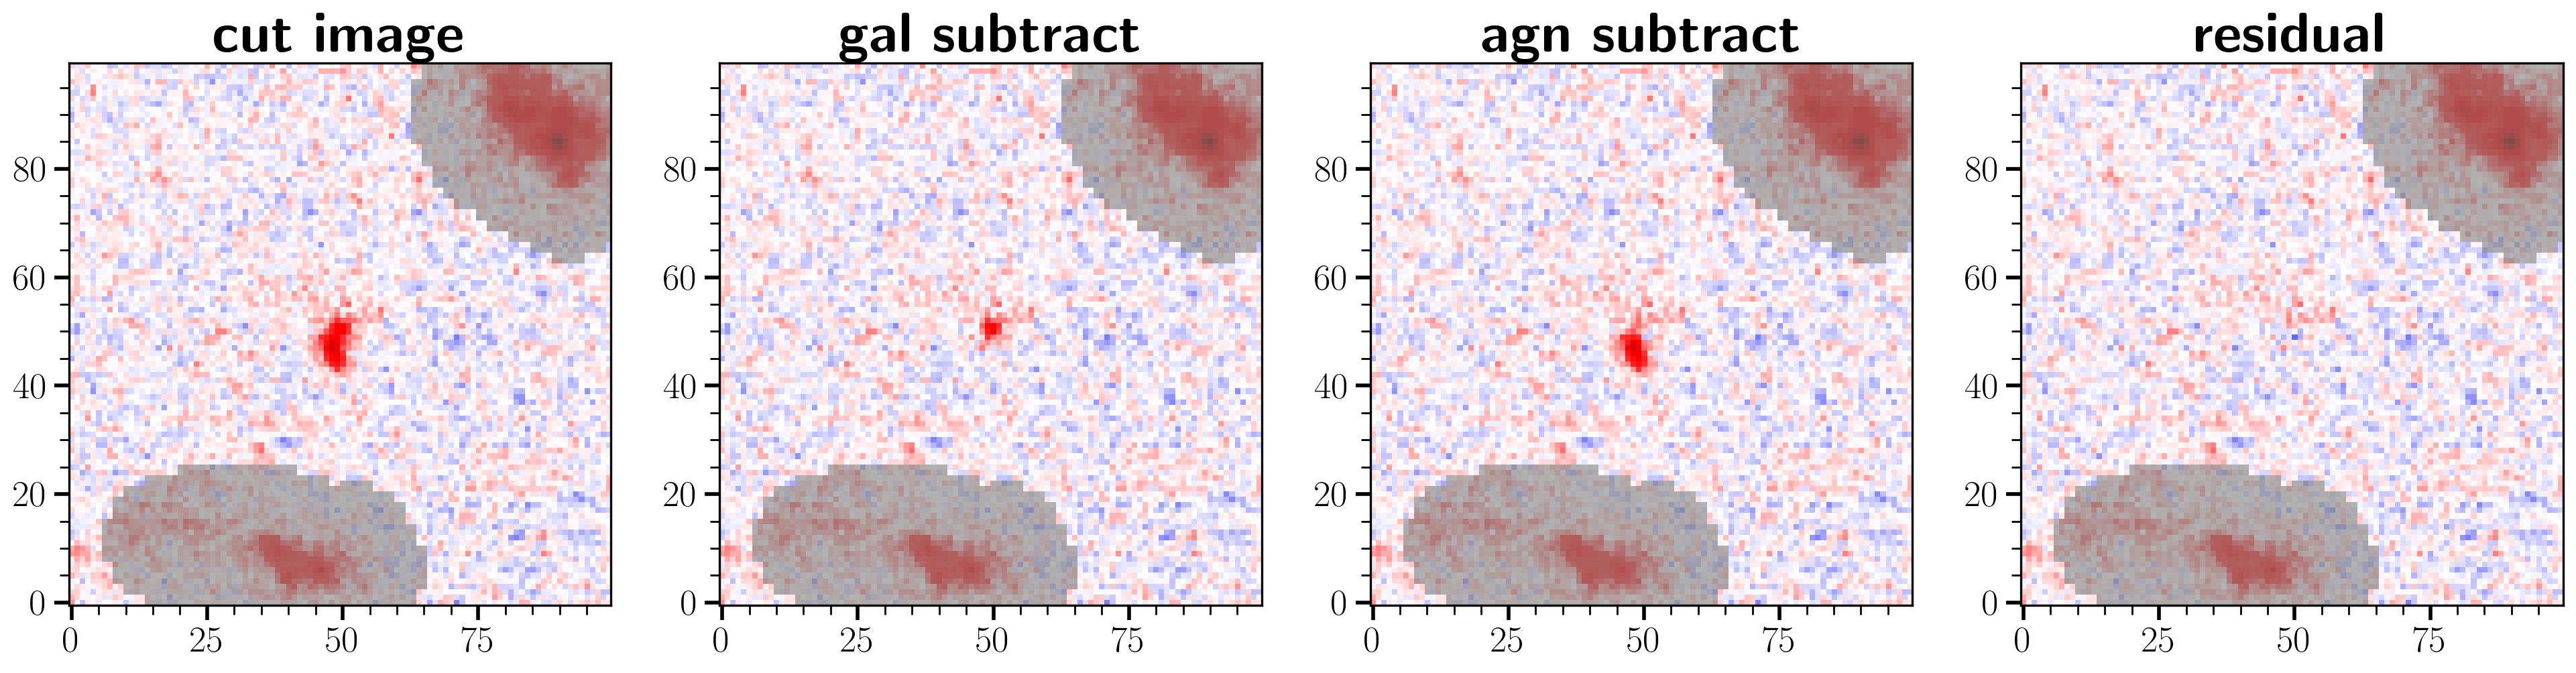

In [4]:
nrow, ncol  = 1, 4
fig, grid   = fig_grid(nrow, ncol)
img_subcom  = cut_img0 - comgal_img0
show_image(img = img_subcom, fig=fig, grid=grid, pos=(0, 0), title="cut image", mask=mask_img)
show_image(img = img_subcom - gal_img0, fig=fig, grid=grid, pos=(0, 1), title="gal subtract", mask=mask_img)
show_image(img = img_subcom - agn_img0, fig=fig, grid=grid, pos=(0, 2), title="agn subtract", mask=mask_img)
show_image(img = img_subcom - gal_img0 - agn_img0, fig=fig, grid=grid, pos=(0, 3), title="residual", mask=mask_img)

## 2. Specturm plot

In [ ]:
## first load spectrums.

pltwave, Sedcomps, Sedlabels, zlist = Myfitter.cal_model_image()
wavephot, fluxphot, errphot, modelphot  = pltwave

gal_model   = Myfitter.get_model("a")
agn_model   = Myfitter.get_model("AGN")
zred    = agn_model.redshift
GSdata  = Myfitter.GSdata
pardict     = Myfitter.pardict
wavegrid    = GSdata.wavegrid
resps   = GSdata.resps

## iso plot to avoid flux from other sources and background residual.
iso_phot_fluxs_llo  = [] ## llo means Luminosity lambda in observe frame (unit: 1e38)
iso_phot_models_llo = []
iso_phot_errs_llo   = []
iso_scales  = []
segm_plot   = 0

for loop_f, gs_filter in enumerate(GSdata.allbands): # only one image group here. 


    resp    = resps[loop_f]
    image_atlas     = GSdata.image_atlas_list[0]
    im              = GSdata.get_image(gs_filter)

    coord_transpar  = im.coordinates_transfer_para
    PSF     = im.PSF
    PHY2CR  = im.phys_to_counts_rate # factor converting Llo to image unit.(counts_rate means image unit, no matter what unit image actually are.)
    cut_image = im.cut_image
    err_image = im.cut_sigma_image
    shape   = im.cut_image.shape

    xagn, yagn  = pardict[f"xcen_{agn_model.prefix}"], pardict[f"ycen_{agn_model.prefix}"] # for shifting point source.
    
    gal_img     = gal_model.generate_image(Myfitter.GSdata, band=gs_filter, noSED=False, pardict=pardict) 
    agn_img     = agn_model.generate_image(posi=[xagn, yagn], shape=shape, band=gs_filter, psfimage=PSF, resp=resp, wavegrid=wavegrid, 
                                        transpar=coord_transpar, pardict=pardict, ) * PHY2CR 

    agn_host_model  = agn_img + gal_img


    model_phots_llo = np.sum(agn_host_model) / PHY2CR
    model_phots_flam    = Ll38_to_flam(model_phots_llo, zred)
    
    threshold   = 0.03*np.max(agn_host_model, ) # for segm detection.
    segm    = detect_sources(agn_host_model, threshold, npixels=10)

    segm_plot   = segm.data if loop_f == 0 else segm_plot

    ## only care the flux in segm region.
    iso_phot_llo    = np.sum(cut_image[segm.data > 0]) / PHY2CR
    iso_phot_flam   = Ll38_to_flam(iso_phot_llo, zred)
    iso_phot_model_llo      = np.sum(agn_host_model[segm.data>0]) / PHY2CR
    iso_phot_model_flam     = Ll38_to_flam(iso_phot_model_llo, zred)
    iso_phot_err_llo    = np.sqrt(np.sum(err_image[segm.data>0] ** 2)) / PHY2CR
    iso_phot_err_flam   = Ll38_to_flam(iso_phot_err_llo, zred)

    iso_phot_fluxs_llo.append(iso_phot_flam)
    iso_phot_models_llo.append(iso_phot_model_flam)
    iso_phot_errs_llo.append(iso_phot_err_flam)
    iso_scales.append(iso_phot_model_flam / model_phots_flam) 


iso_phot_fluxs_llo  = np.array(iso_phot_fluxs_llo)
iso_phot_models_llo = np.array(iso_phot_models_llo)
iso_phot_errs_llo   = np.array(iso_phot_errs_llo)
iso_scales  = np.array(iso_scales)
iso_scale   = np.mean(iso_scales) ## used to scale spectrum. TODO: should be optimized here. 

Find galaxy model a
Find agn model AGN


[]

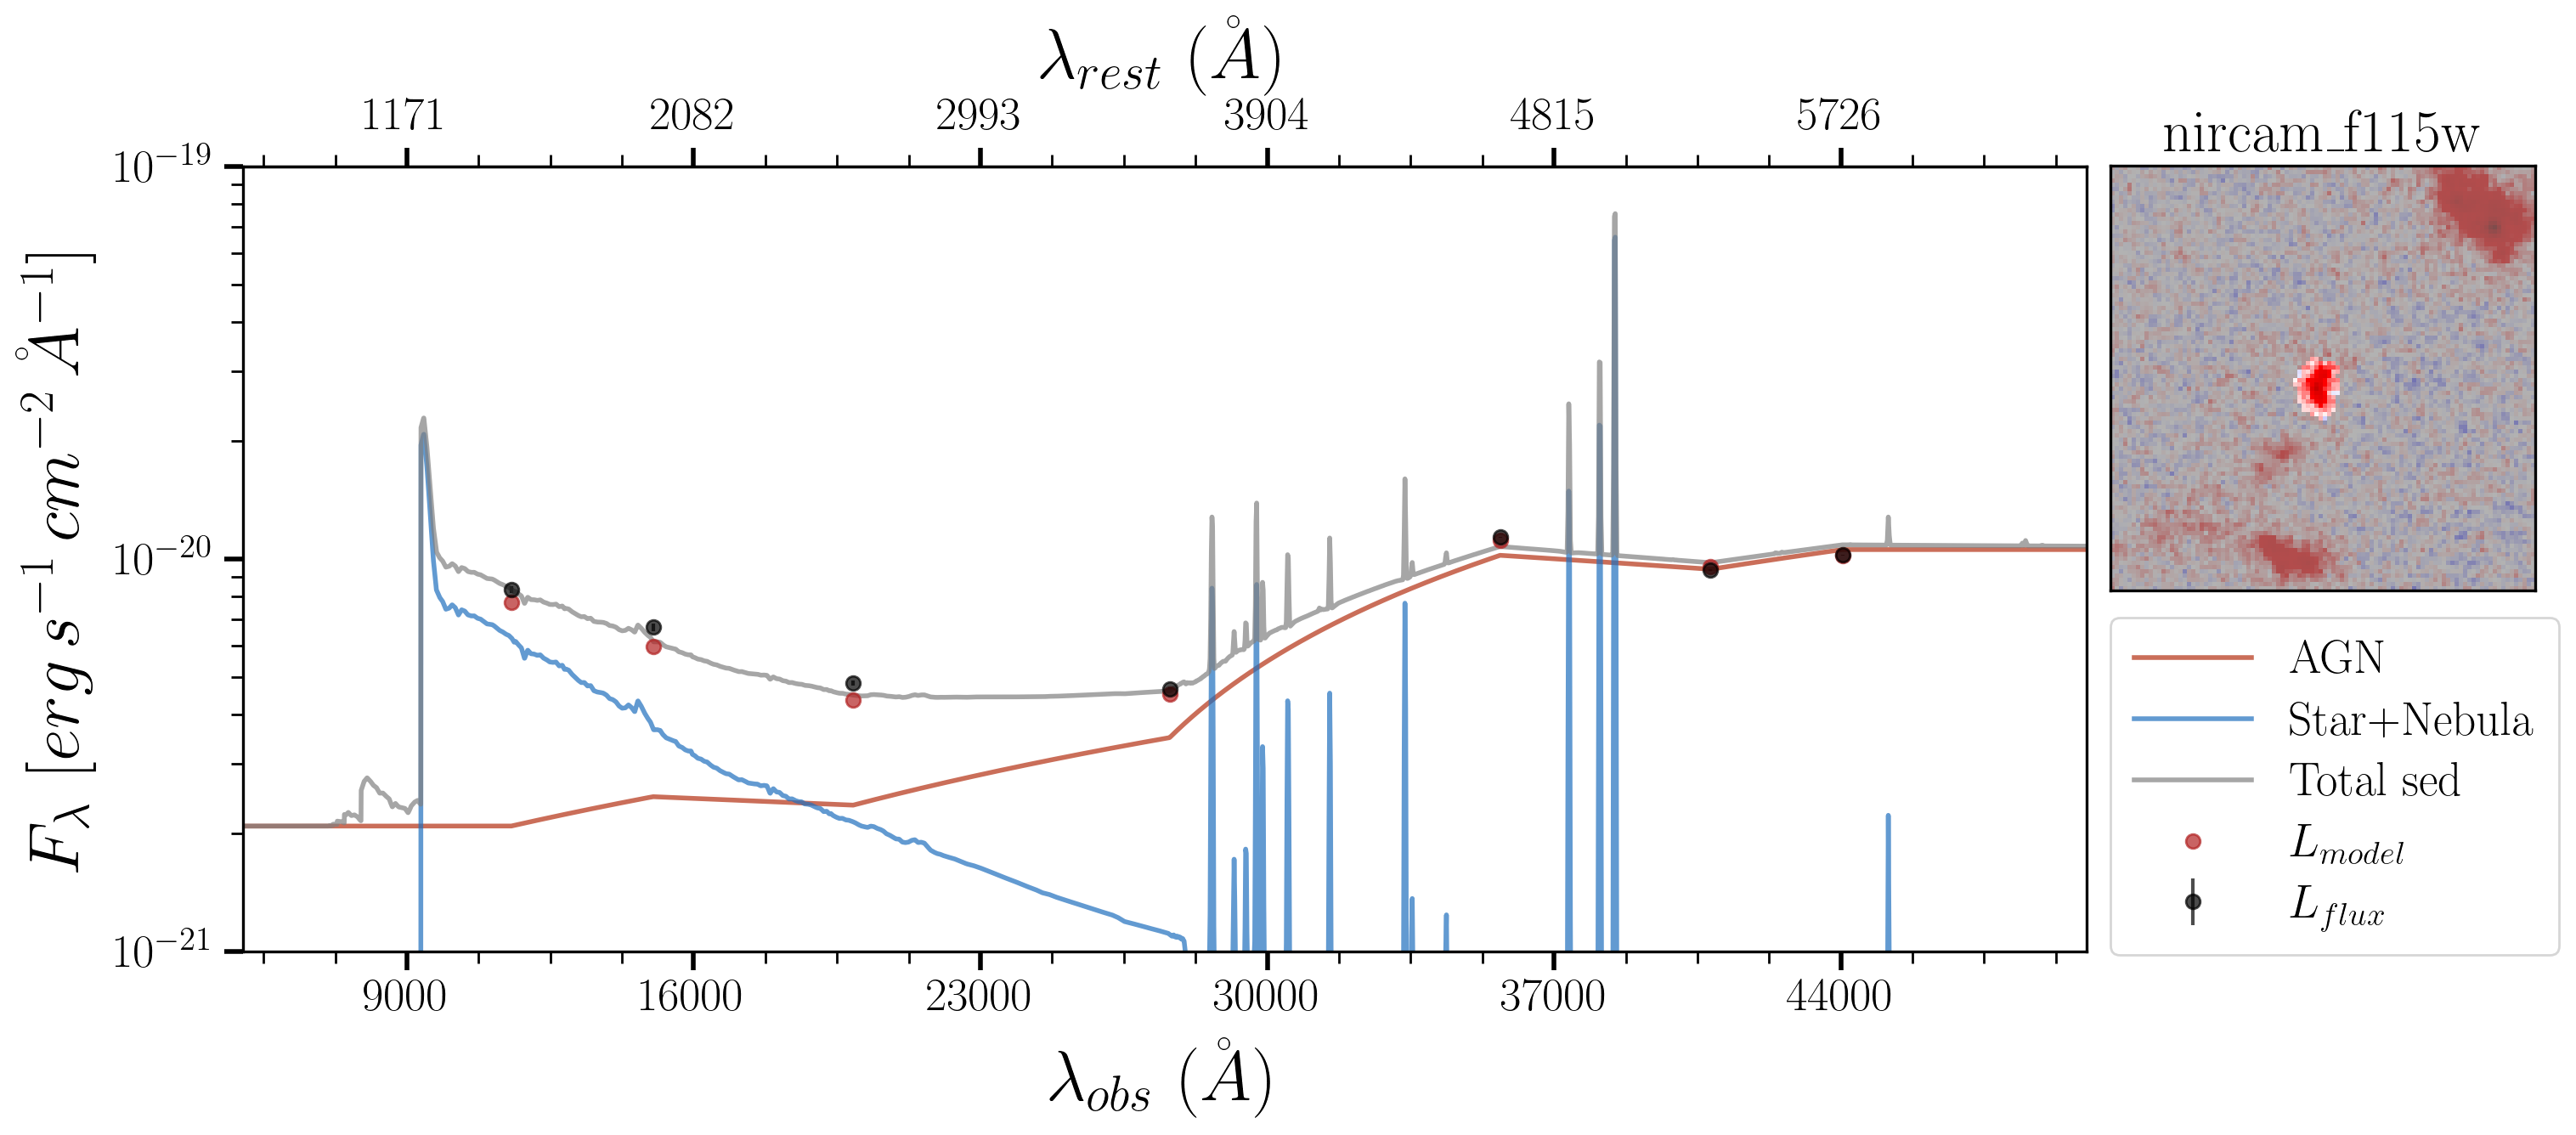

In [6]:
sed_total   = np.zeros_like(wavegrid)

Sedlabels_wanted    = ['AGN', 'disk_SteNeb_att',]
write_labels    = ["AGN", "Star+Nebula"]
color_list      = ["#B43012", "#1F6FBE"]


fig, ax     = plt.subplots(figsize = (14, 6))

for loop in range(len(Sedlabels)):
    if Sedlabels[loop] in Sedlabels_wanted:
        
        want_index  = Sedlabels_wanted.index(Sedlabels[loop])
        sedlabel    = write_labels[want_index]
        color       = color_list[loop]

        sed_subC    = np.array(Sedcomps[loop])
        sed_flam    = Ll38_to_flam(sed_subC, zred)
        sed_flam   *= iso_scale

        ax.plot(wavegrid, sed_flam, color = color,  label = sedlabel, lw = 2, alpha = 0.7, )
        sed_total += sed_flam


ax.errorbar(wavephot, iso_phot_models_llo, color="firebrick", label = r"$L_{model}$", fmt = "o", alpha = 0.7)
ax.errorbar(wavephot, iso_phot_fluxs_llo, color="black", yerr = iso_phot_errs_llo, label = r"$L_{flux}$", fmt= "o", alpha = 0.7)

ax.plot(wavegrid, sed_total, color="grey", label = "Total sed", lw = 2, alpha = 0.7)
ax.set_ylabel(r"$F_\lambda \,\, [erg \, s^{-1} \, cm^{-2} \, \AA^{-1}]$", fontsize = 30)
ax.set_xlabel(r"$\lambda_{obs}$ ($\AA$)", fontsize=30,)

xaxis_label    = np.arange(9000, 50000, 7000)

ax.set_ylim(1e-21, 1e-19)
ax.set_xlim([5000, 50000])
ax.set_xticks(xaxis_label, labels=[f"{w:.0f}" for w in xaxis_label])
ax.tick_params(axis="x", labelsize=20, rotation=0, )
ax.tick_params(axis='both', which="major", direction="out", width=2, length=8)
ax.tick_params(axis='both', which="minor", direction="out", width=1, length=5)
ax.tick_params(which="both", right=False)
# ax.yaxis.
ax.set_yscale("log")
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.21), fontsize=20, numpoints=1, frameon=True)


ax2 = ax.secondary_xaxis("top", functions=(lambda x: x/(1+zred), lambda x: x*(1+zred)))
rest_xaxis_label    = xaxis_label / (1+zred)
ax2.set_xticks(rest_xaxis_label, labels=[f"{w:.0f}" for w in rest_xaxis_label])
ax2.set_xlabel(r'$\lambda_{rest}$ ($\AA$)', fontsize=30)
ax2.tick_params(axis="x", labelsize=20, rotation=0)
ax2.tick_params(axis="x", which="both", direction="out")
ax2.tick_params(axis="x", which="major", width=2, length=8)
ax2.tick_params(axis="x", which="minor", width=1, length=5)


ax_insert = inset_axes(ax, width=2.5, height=2.5, loc='center left',bbox_to_anchor=(1, 0.73), bbox_transform=ax.transAxes)
# norm 
_, _, sky_std   = sigma_clipped_stats(cut_img0, sigma=3.0, maxiters=5)
immin, immax    = 5 * sky_std, np.nanmax(cut_img0)


ax_insert.imshow(normimg(cut_img0, immin, immax, ), cmap='seismic', origin='lower', vmin=-1, vmax=1,interpolation='nearest')
mask    = np.array(segm_plot == 0, dtype=float)
m_vis   = np.ma.masked_where(mask == 0, mask)  # hide unmasked pixels (0)
shade   = mcolors.ListedColormap(["grey"])
ax_insert.imshow(m_vis, cmap=shade, origin="lower", alpha=0.6, interpolation="nearest", vmin=0, vmax=1)
ax_insert.set_title("nircam_f115w", fontsize = 25)
ax_insert.set_xticks([])
ax_insert.set_yticks([])

## 3. SFH plot
- MCMC SFH
- nest sampling SFH 

#### 3.1 MCMC SFH
- directly convert f_cont_list to SFH

In [16]:
from utils import parse_gs_params
from galfits.gsutils import z_to_agebin, _generate_cosmic_sfh_prior

gal_model   = Myfitter.get_model("a")
pro_name    = gal_model.subnames[0] # only one profile ["disk"]

zred    = gal_model.redshift
nbins   = 7
age_list    = z_to_agebin(zred, nbins)

f_cont_names    = [f"{pro_name}_f_cont_bin{loop_f+1}" for loop_f in range(nbins)]
f_cont_list     = parse_gs_params(gssum_path, f_cont_names)
logM    = parse_gs_params(gssum_path, [f"logM_{pro_name}"])
SFH_list    = fconts_to_SFH(f_cont_list, age_list, logM)
SFH_list_plot   = np.append(SFH_list, [0, 0])
age_list_plot   = np.append(age_list, max(age_list)+3)

# cosmic prior 
f_cont_prior    = _generate_cosmic_sfh_prior(zred, age_list, logM, )
sfh_prior   = fconts_to_SFH(f_cont_prior, age_list, logM)
sfh_prior_plot  = np.append(sfh_prior, [0,0])


Find galaxy model a


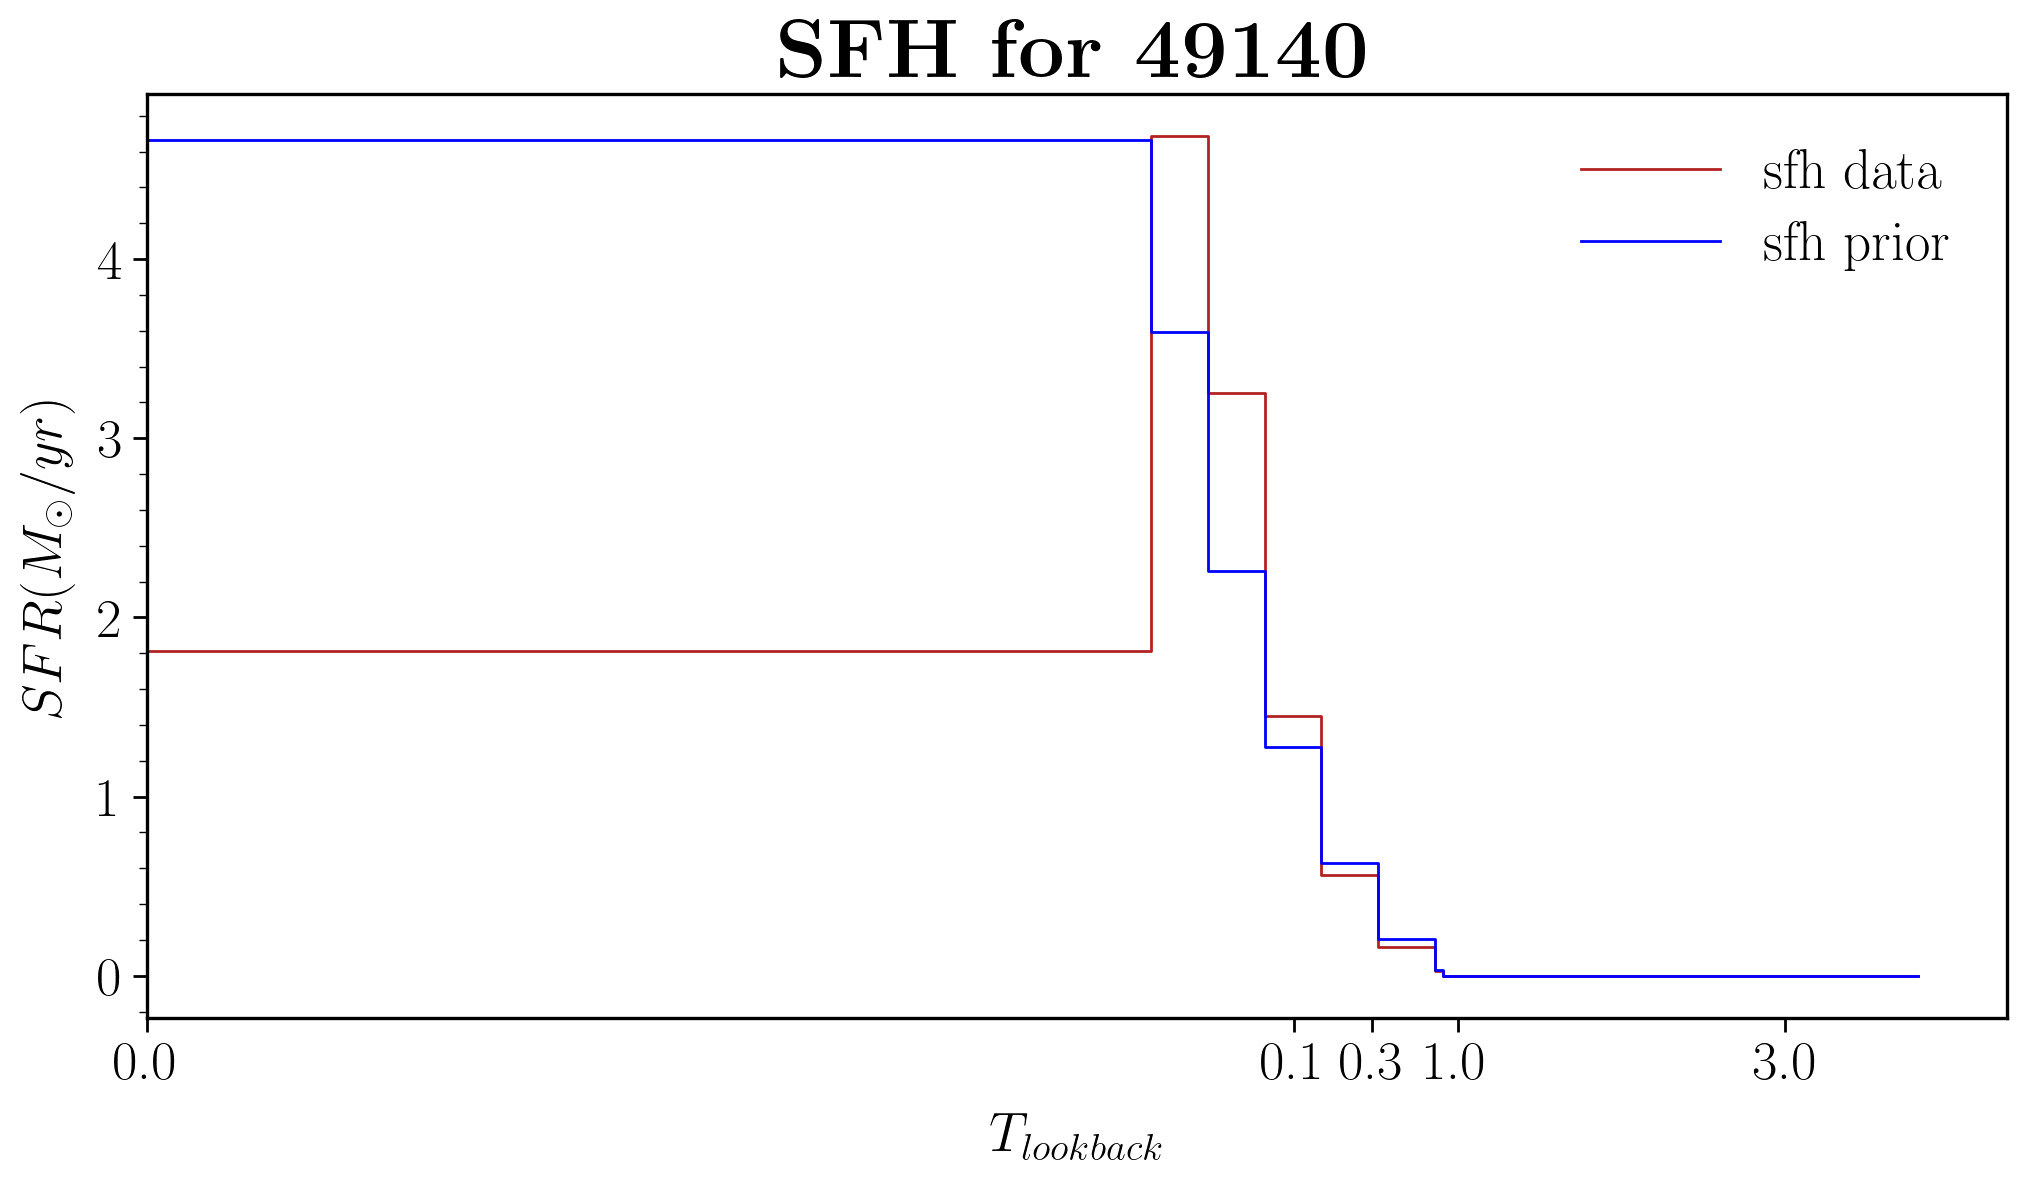

In [20]:
fig, ax_sfh     = plt.subplots(figsize=(12,6))
ax_sfh.step(age_list_plot, SFH_list_plot, where="post", color="firebrick", linewidth=1,label="sfh data")
ax_sfh.step(age_list_plot, sfh_prior_plot, where="post", color="blue", linewidth=1,label="sfh prior")

# ax_sfh.scatter(age_list, SFH_list_plot)
ax_sfh.set_xscale("function", functions=(forward, inverse))

ax_sfh.set_xlabel(r"$T_{lookback}$", fontsize=20)
ax_sfh.set_ylabel(r"$SFR(M_\odot / yr)$", fontsize=20)

xtick_labels    = [0,0.1, 0.3, 1, 3]
ax_sfh.set_xticks(xtick_labels, labels=[f"{x:.1f}" for x in xtick_labels])

ax_sfh.tick_params(axis="both", which="major", size=5, width=1)
ax_sfh.tick_params(axis="y", which="minor", size=3, width=0.5)
ax_sfh.tick_params(axis="x", which="minor", size=3, width=0)
ax_sfh.set_title(B("SFH for 49140"))
# ax_sfh.set_xlim(0, 1.5)
ax_sfh.legend()